## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(r"C:\Users\SAMSUNG\Desktop\DSML_Lab\Week2\Day5\lab-eda-bivariate\amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [133]:
num=df.select_dtypes(include="number")
cat=df.select_dtypes(exclude="number")

In [6]:
cat['category'].unique()

array(['Hi-Fi Speakers', 'CD, Disc & Tape Players', 'Wearable Technology',
       'Light Bulbs', 'Bathroom Lighting',
       'Heating, Cooling & Air Quality', 'Coffee & Espresso Machines',
       'Lab & Scientific Products', 'Smart Speakers',
       'Motorbike Clothing', 'Motorbike Accessories',
       'Motorbike Batteries', 'Motorbike Boots & Luggage',
       'Motorbike Chassis', 'Handmade Home & Kitchen Products',
       'Hardware', 'Storage & Home Organisation',
       'Fireplaces, Stoves & Accessories', 'PC Gaming Accessories',
       'USB Gadgets', 'Blank Media Cases & Wallets', 'Car & Motorbike',
       'Boys', 'Sports & Outdoors', 'Microphones', 'String Instruments',
       'Karaoke Equipment', 'PA & Stage',
       'General Music-Making Accessories', 'Wind Instruments',
       'Handmade Gifts', 'Fragrances', 'Calendars & Personal Organisers',
       'Furniture & Lighting', 'Computer Printers', 'Ski Goggles',
       'Snowboards', 'Skiing Poles', 'Downhill Ski Boots',
       'Hiki

In [9]:
cat.head()


,asin,title,isBestSeller,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",True,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",False,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,False,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


In [88]:
table1=pd.crosstab(df['category'], df['isBestSeller'], normalize=True).sort_values(by=True, ascending=False).round(5)
table2=table1.head(20)

In [ ]:
#Table1 shows that the Grocery is the most prevalent in the best-selling category, next to the category Health&Personal Care, Baby, Sports&Outdoors etc

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Figure size 3000x1000 with 0 Axes>

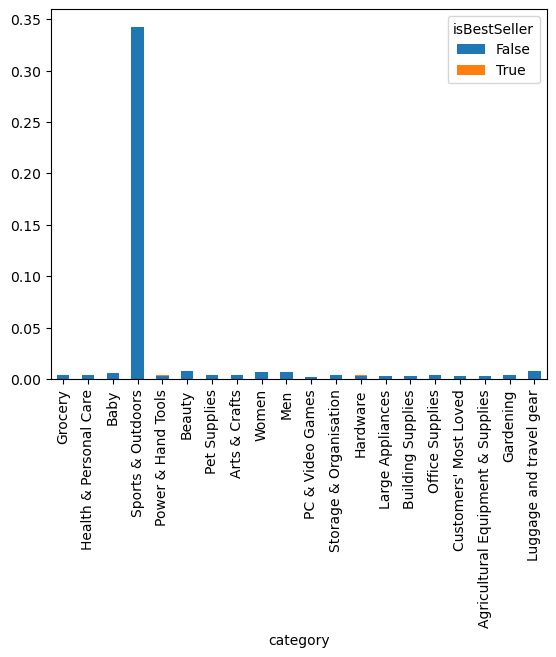

In [89]:
plt.figure(figsize=(30, 10))
table2.plot(kind='bar', stacked=True)
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.


0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [4]:
df1=df.copy()

In [5]:
df1['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [6]:
Q1 = df1['price'].quantile(0.25)
Q3 = df1['price'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for the outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify the outliers
outliers = df1['price'][(df1['price'] < lower_bound) | (df1['price'] > upper_bound)]

In [7]:
#filtering the outliers from the df_price dataframe
df_price=df1[df1.filter(['price'])['price'].between(lower_bound, upper_bound)]

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [8]:
pricetable=pd.crosstab(df_price['category'], df_price['price'])
pricetable

price,0.00,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,...,99.90,99.91,99.92,99.93,99.94,99.95,99.96,99.97,99.98,99.99
category,,,,,,,,,,,,,,,,,,,,,
3D Printers,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3D Printing & Scanning,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Abrasive & Finishing Products,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Action Cameras,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,12
Adapters,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Wind Instruments,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Window Treatments,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Women,0,0,0,0,0,0,0,0,0,0,...,2,0,0,0,0,0,0,0,2,7


In [9]:
#total value count for each row *axis=1
pricetable.sum(axis=1).nlargest(20)

category
Sports & Outdoors                         694092
Beauty                                     19233
Bath & Body                                19050
Manicure & Pedicure Products               18904
Handmade Clothing, Shoes & Accessories     18811
Make-up                                    18718
Skin Care                                  18686
Hair Care                                  18625
Birthday Gifts                             18398
Handmade Gifts                             17948
Handmade Home Décor                        17675
Luggage and travel gear                    17557
Women                                      17476
Fragrances                                 17431
Handmade Kitchen & Dining                  17346
Handmade Artwork                           17269
Handmade Home & Kitchen Products           17175
Handmade Jewellery                         17135
Men                                        16596
Baby                                       14883
dtype: int6

In [10]:
#the index of top20 category will be saved as top20
top20=pricetable.sum(axis=1).nlargest(20).index
top20

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object', name='category')

In [11]:
#from the df_price dataframe, top20 category are selected
df_top20=df_price[df_price['category'].isin(top20)]
df_top20

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_23912\2602674787.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, y='price', x='category', palette='coolwarm', legend=True)


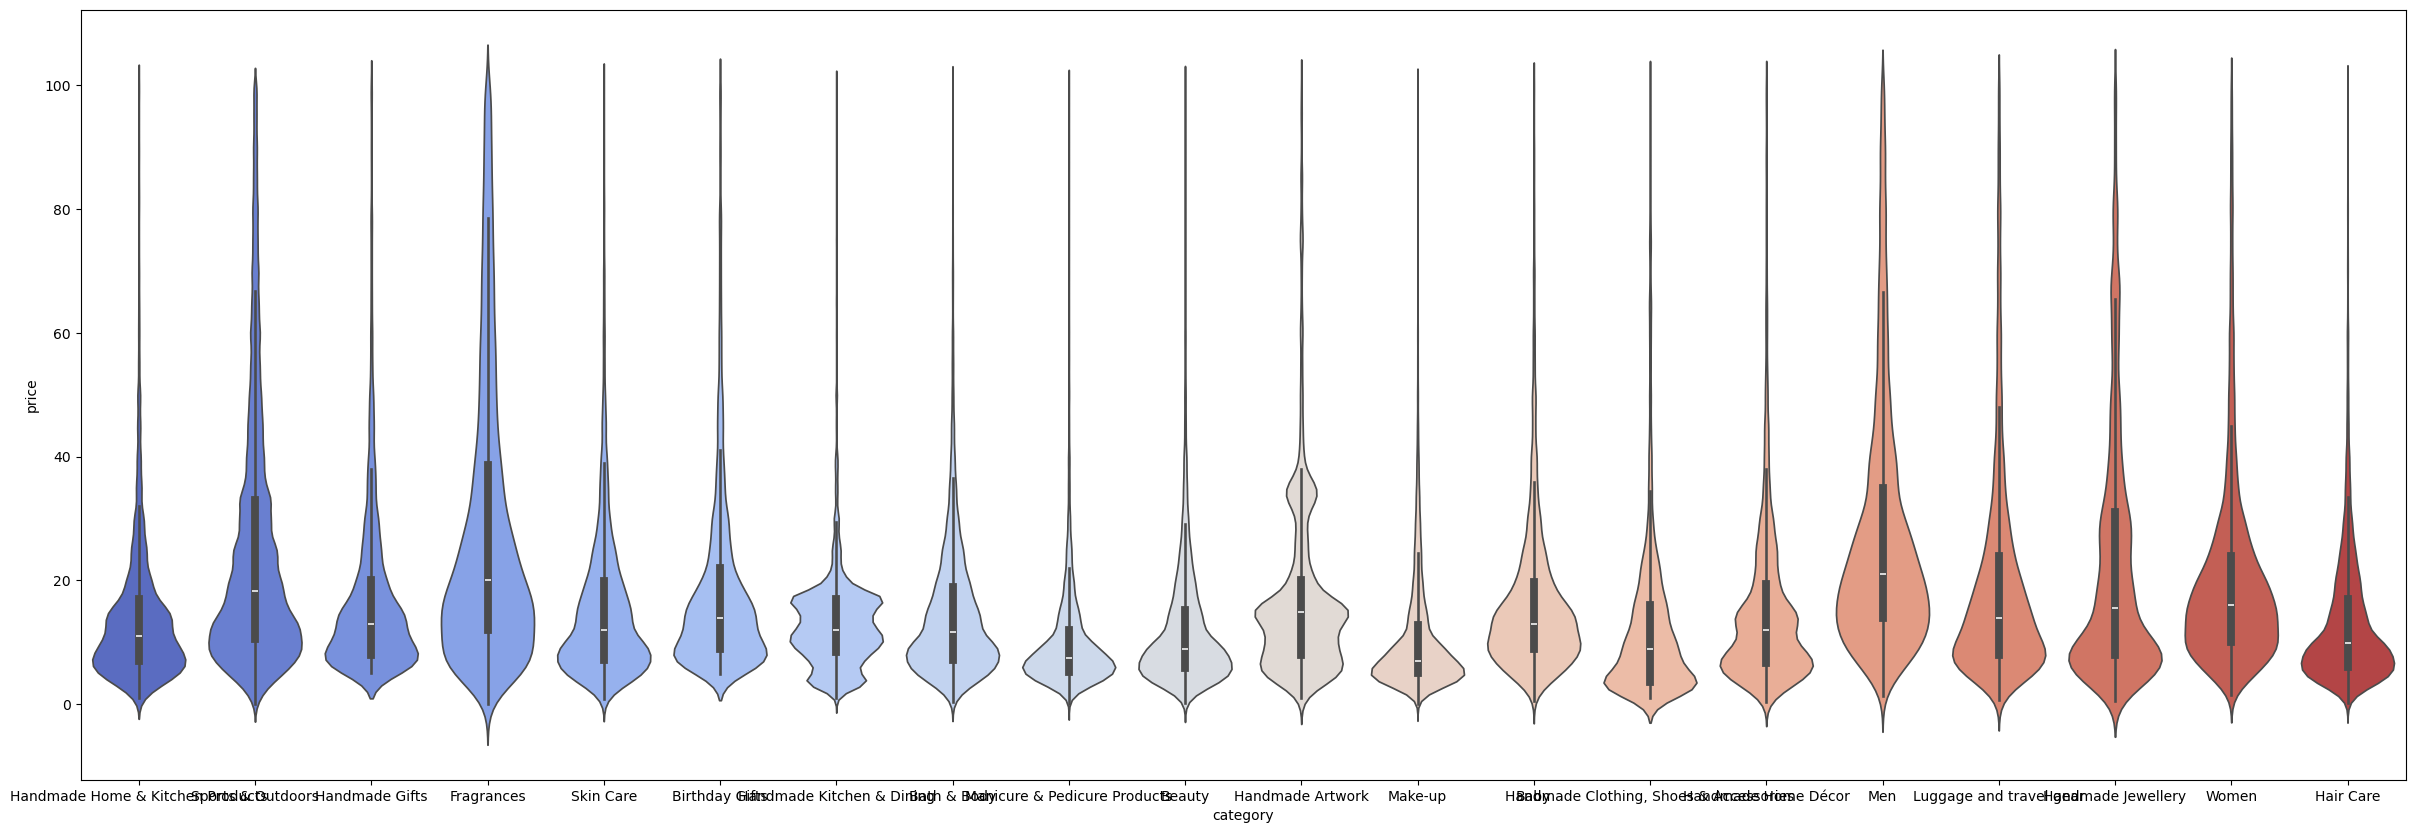

In [12]:
plt.figure(figsize=(30, 10))
sns.violinplot(data=df_top20, y='price', x='category', palette='coolwarm', legend=True)
plt.show()

- Which product category tends to have the highest median price? Don't filter here by top categories.

In [13]:
medianprice=df_price[['category','price']].groupby('category').agg('median').sort_values(by='price', ascending=False)
highestmedianprice=medianprice.head(1)
#Desktop PCs is the highest median price
highestmedianprice

,price
category,
Desktop PCs,74.0


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

In [14]:
df_price.sort_values(by='price', ascending=False)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
2232551,2579883,B0B8PD95K3,"Kodak PIXPRO FZ45 1/2.3"" Appareil-photo compac...",3.6,105,99.99,False,0,Digital Cameras
906996,987657,B0CBCP4HVG,Trespass Mens Hooded Activewear Outdoor Jacket...,0.0,0,99.99,False,0,Sports & Outdoors
2232748,2580080,B08D6QYBN3,AGFA PHOTO Realishot WP8000 Waterproof Digital...,5.0,1,99.99,False,0,Digital Cameras
2232682,2580014,B0BHT56TLX,"Sunscien Autofocus Digital Camera, 4K 48MP Vlo...",4.4,408,99.99,False,0,Digital Cameras
2232504,2579834,B0B8PD8TTP,"Kodak PIXPRO FZ45 1/2.3"" Appareil-photo compac...",4.0,131,99.99,False,0,Digital Cameras
...,...,...,...,...,...,...,...,...,...
1696245,1910119,B07VHSVDTY,How Not to Diet: The Groundbreaking Science of...,4.7,6187,0.00,False,0,Sports Supplements
830795,905932,B0BJQQZ79H,Battle of the Fang: Space Marine Battles: Warh...,4.6,166,0.00,False,0,Games & Game Accessories
1075630,1187147,B0BQHJN9KP,DMR - Digital Mobile Radio Explained BTECH DMR...,4.6,3,0.00,False,0,Radio Communication
1181667,1306244,B002SQBB7A,The Gruffalo Song & Other Songs,4.2,142,0.00,False,0,Piano & Keyboard


In [ ]:
#sorting the index for top10category based on the count
top10index=pricetable.sum(axis=1).sort_values(ascending=False).nlargest(10).index
top10index

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')

In [ ]:
#top10 category and calculate their mean price
df_top10=df_price[df_price['category'].isin(top10index)]
top10meanprice=df_top10[['category', 'price']].groupby('category').mean()

C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_23912\3978081389.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10meanprice, x="category", y="price", palette="coolwarm", errorbar=None)


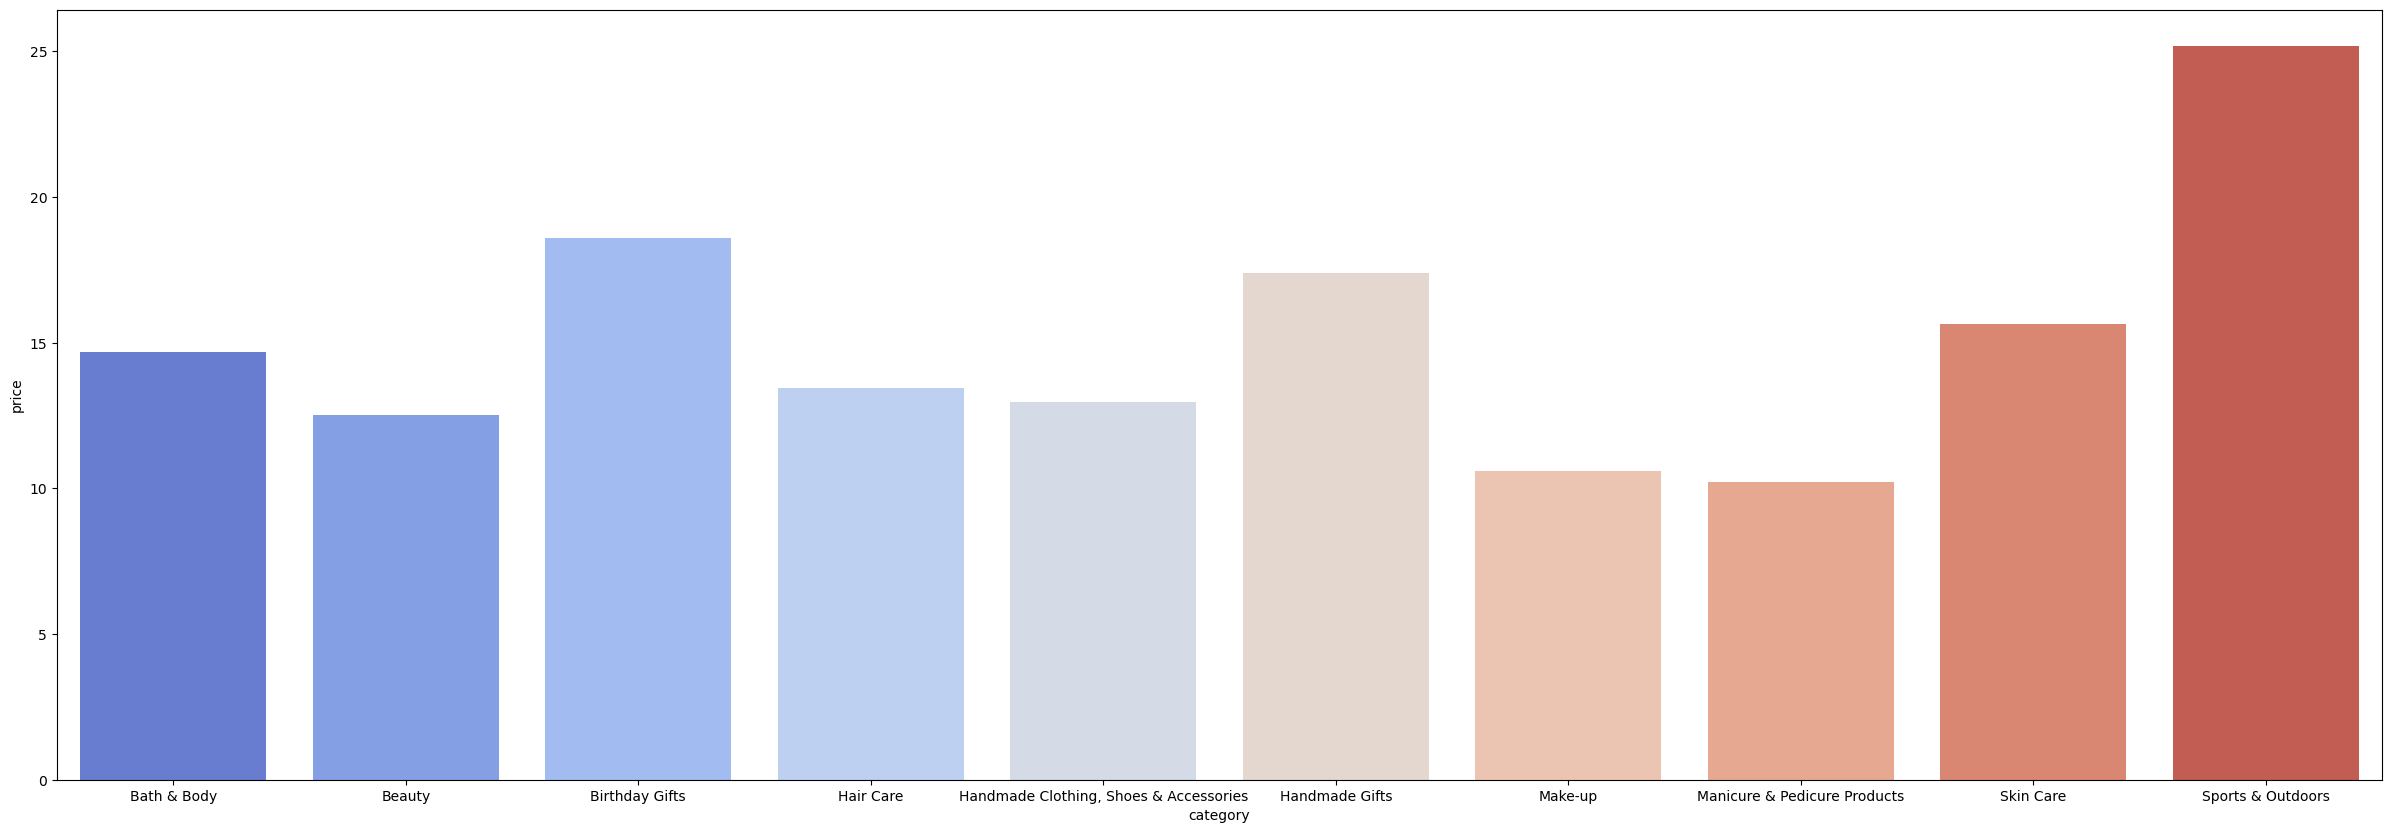

In [24]:
plt.figure(figsize=(30, 10))
sns.barplot(data=top10meanprice, x="category", y="price", palette="coolwarm", errorbar=None)
plt.show()

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_23912\3902896379.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x="category", y="stars", palette="coolwarm", legend=True)


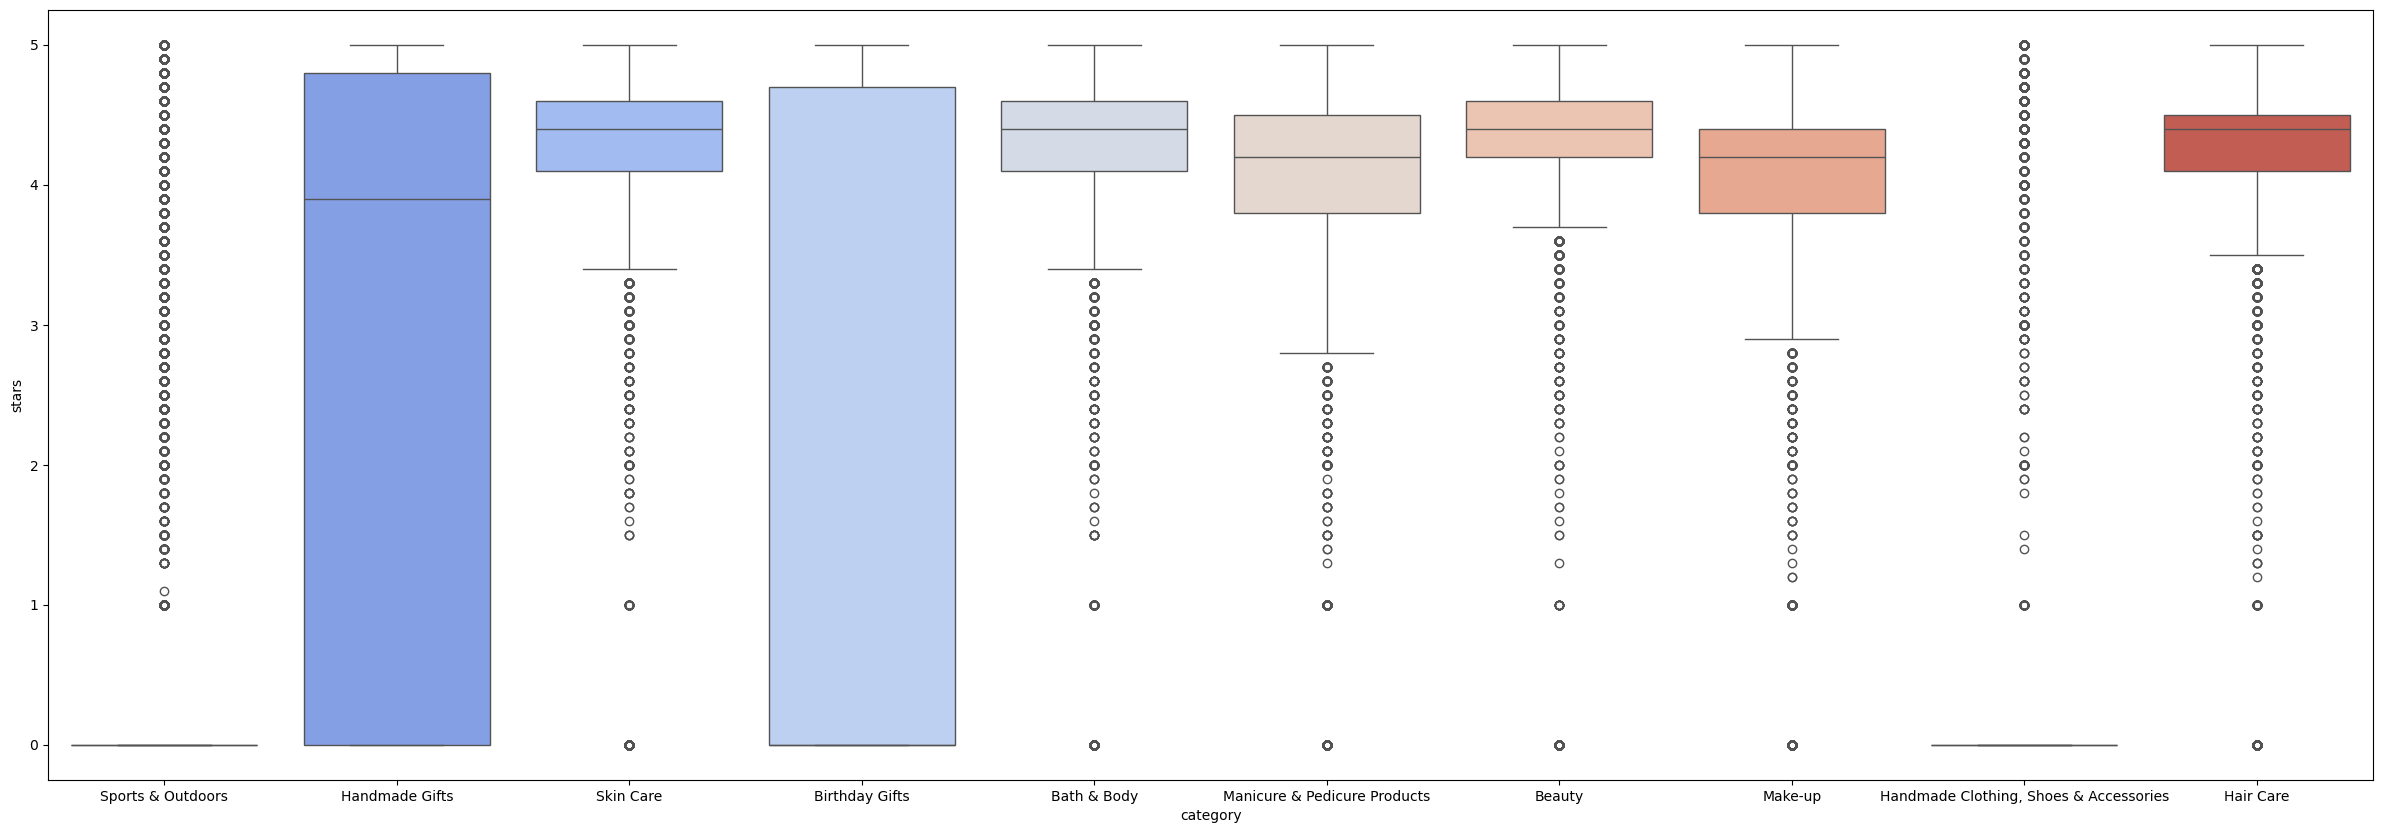

In [33]:
plt.figure(figsize=(30, 10))
sns.boxplot(data=df_top10, x="category", y="stars", palette="coolwarm", legend=True)
plt.show()

In [ ]:
#the highest median raiting from customers
df_top10[['category', 'stars']].groupby('category').median().sort_values(by='stars', ascending=False)

,stars
category,
Bath & Body,4.4
Beauty,4.4
Hair Care,4.4
Skin Care,4.4
Make-up,4.2
Manicure & Pedicure Products,4.2
Handmade Gifts,3.9
Birthday Gifts,0.0
"Handmade Clothing, Shoes & Accessories",0.0


### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

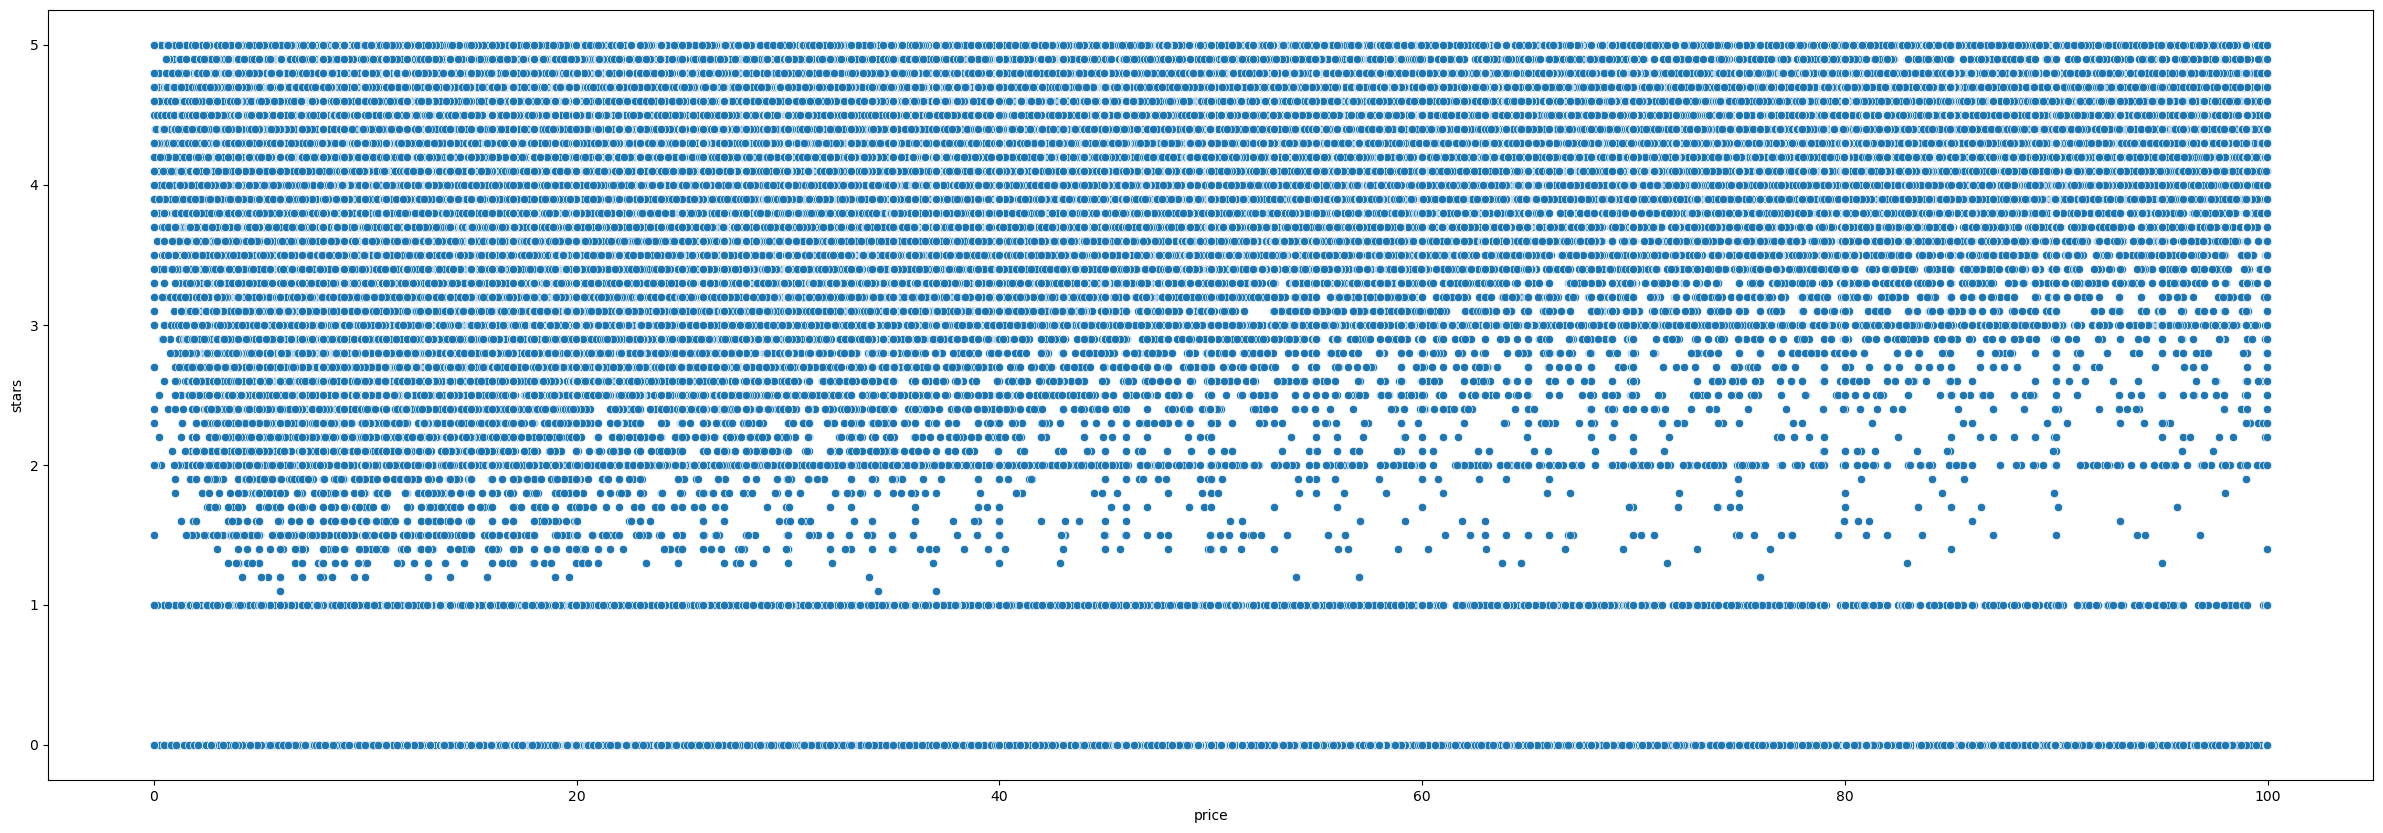

In [ ]:
plt.figure(figsize=(30, 10))
sns.scatterplot(data=df_price, x='price', y='stars')
plt.show()
#I don't see any relationship between product rating and price based on scatter plot

In [41]:
num_df_price=df_price.select_dtypes(include='number')
num_df_price

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [44]:
matrix=num_df_price.corr()

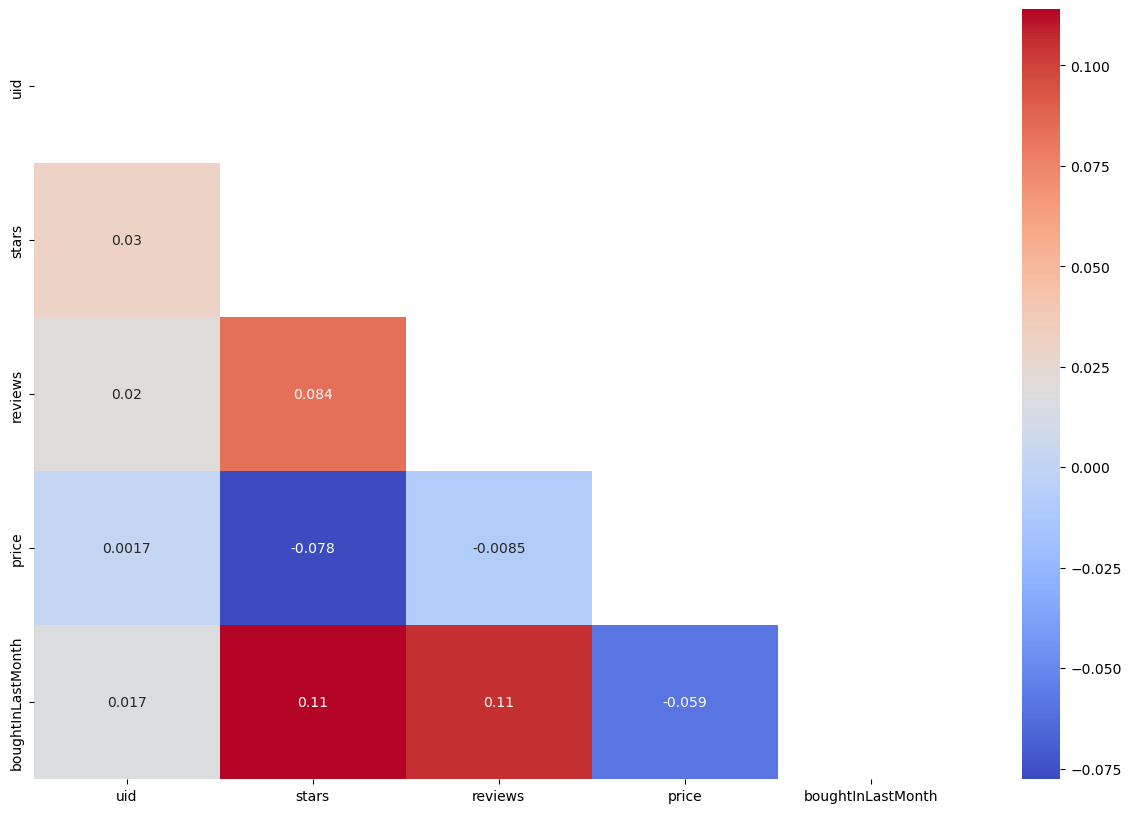

In [47]:
mask=np.triu(np.ones_like(matrix, dtype=bool))
plt.figure(figsize=(15,10))
sns.heatmap(matrix, mask=mask, annot=True, cmap='coolwarm')
plt.show()

In [50]:
%pip install statsmodels

In [51]:
import statsmodels.api as sm

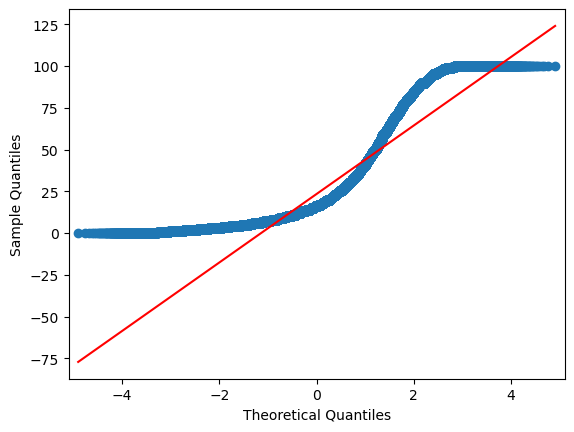

In [52]:
sm.qqplot(df_price['price'], line='s')
plt.show()

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?
